In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import MultinomialNB
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('spam.csv', encoding='ISO-8859-1')
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
df = df.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1)

In [4]:
df.sample(5)

,v1,v2
3102,ham,"U so lousy, run already come back then half de..."
4847,ham,S.this will increase the chance of winning.
1116,ham,Hey... What time is your driving on fri? We go...
1881,ham,Ok.. ÌÏ finishing soon?
3433,ham,Sending you greetings of joy and happiness. Do...


In [5]:
df.columns = ['labels', 'data']

In [6]:
df.head()

,labels,data
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


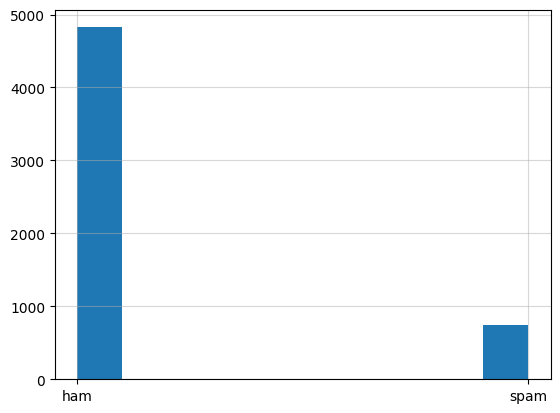

In [7]:
df['labels'].hist()
plt.grid(alpha=0.5)
plt.show()

In [8]:
# Create binary labels
df ['b_labels'] = df['labels'].map({'ham': 0, 'spam': 1})
Y = df['b_labels'].to_numpy()

In [9]:
df.head()

,labels,data,b_labels
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## Dataset Split

In [10]:
X_train, X_test, Y_train, Y_test = train_test_split(df['data'], Y, test_size=0.33, random_state=42)

X_train.shape, X_test.shape

((3733,), (1839,))

In [11]:
featurizer = CountVectorizer(decode_error='ignore')

X_train = featurizer.fit_transform(X_train)
X_test = featurizer.transform(X_test)

In [12]:
X_train.shape, X_test.shape

((3733, 7057), (1839, 7057))

## Model Training

In [13]:
model = MultinomialNB()
model.fit(X_train, Y_train)

MultinomialNB()

In [14]:
print("Train Acccuracy: ", model.score(X_train, Y_train))
print("Test Acccuracy: ", model.score(X_test, Y_test))

Train Acccuracy:  0.994910259844629
Test Acccuracy:  0.9825992387166939


In [15]:
y_pred = model.predict(X_test)
print("F1 Score : ", f1_score(Y_test, y_pred))

F1 Score :  0.9338842975206612


In [16]:
print("Classification Report : \n", classification_report(Y_test, y_pred))

Classification Report : 
               precision    recall  f1-score   support

           0       0.98      1.00      0.99      1587
           1       0.97      0.90      0.93       252

    accuracy                           0.98      1839
   macro avg       0.98      0.95      0.96      1839
weighted avg       0.98      0.98      0.98      1839



In [17]:
print("AUC : ", roc_auc_score(Y_test, y_pred))

AUC :  0.9465223392444564


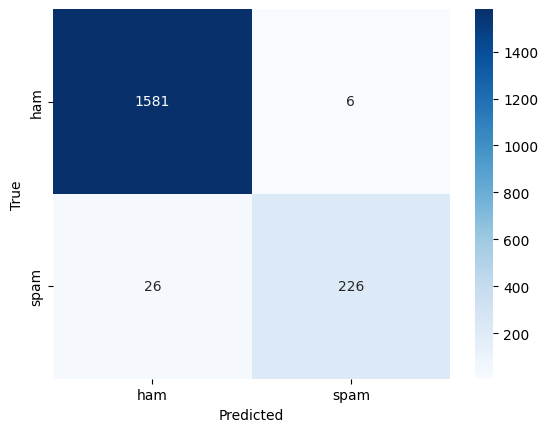

In [18]:
cm = confusion_matrix(Y_test, y_pred)
classes = ['ham', 'spam']
df_cm = pd.DataFrame(cm, index=classes, columns=classes)
ax = sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues')
ax.set_label('Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.show()

In [19]:
def visualize(label):

    words = ''
    for msg in df[df['labels'] == label]['data']:
        msg = msg.lower()
        words += msg + ' '

    wordcloud = WordCloud(width=600, height=400).generate(words)
    plt.figure(figsize=(10, 8), facecolor='k')
    plt.imshow(wordcloud)
    plt.axis('off')
    plt.show()

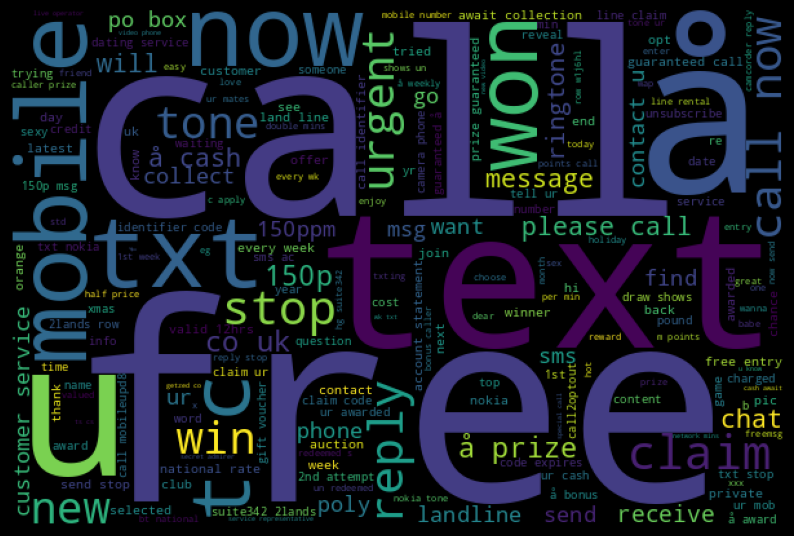

In [20]:
visualize('spam')

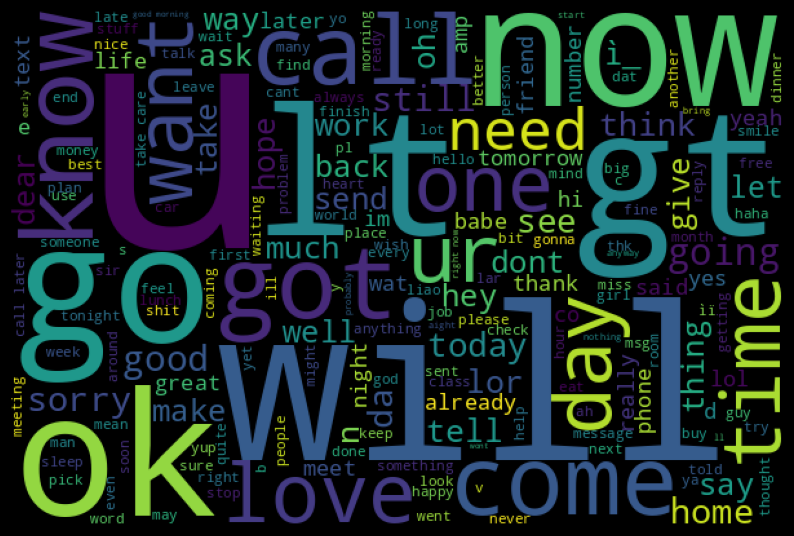

In [21]:
visualize('ham')

In [22]:
X = featurizer.transform(df['data']) 
df['predictions'] = model.predict(X)

In [ ]:
# Messages that are actually spam but predicted as ham

sneaky_spam = df[( df['predictions'] == 0) & (df['b_labels'] == 1)] ['data']
for msg in sneaky_spam:
    print(msg)

FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv
Did you hear about the new \Divorce Barbie\"? It comes with all of Ken's stuff!"
Hi I'm sue. I am 20 years old and work as a lapdancer. I love sex. Text me live - I'm i my bedroom now. text SUE to 89555. By TextOperator G2 1DA 150ppmsg 18+
Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripiton drvgsTo listen to email call 123
Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?
Ever thought about living a good life with a perfect partner? Just txt back NAME and AGE to join the mobile community. (100p/SMS)
Hello. We need some posh birds and chaps to user trial prods for champneys. Can i put you down? I need your address and dob asap. Ta r
Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Callså£1/minmoremobsEMSPOBox45P

In [ ]:
# Messages that are actually ham but predicted as spam

not_actually_spam = df[( df['predictions'] == 1) & (df['b_labels'] == 0)] ['data']
for msg in not_actually_spam:
    print(msg)

Yes:)from last week itself i'm taking live call.
Waiting for your call.
We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us
Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May
Total video converter free download type this in google search:)
Madam,regret disturbance.might receive a reference check from DLF Premarica.kindly be informed.Rgds,Rakhesh,Kerala.
Unlimited texts. Limited minutes.
Mathews or tait or edwards or anderson
Have you laid your airtel line to rest?
I liked the new mobile
Anytime...
Nokia phone is lovly..
We have sent JD for Customer Service cum Accounts Executive to ur mail id, For details contact us
